**Лабораторна робота № 6**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Результати обчислень і висновки наведено нижче.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display,Markdown

Для Colab перед першим запуском за потреби виконайте в окремій клітинці: `%pip install imbalanced-learn xgboost lightgbm catboost`. Код використовує API scikit-learn 1.6 та imbalanced-learn 0.13 або сумісні новіші версії.

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [2]:
file=Path('diabetes_prediction_dataset.csv')
if not file.exists():file=Path('Джерельні файли')/file
if not file.exists():file='https://raw.githubusercontent.com/NANITH777/Diabetes-Prediction-ID3_Alg-ML-Models/main/diabetes_prediction_dataset.csv'

In [3]:
df=pd.read_csv(file)
print('Дані:',df.shape)
display(df.head())

Дані: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Використано перший спосіб: CSV-файл. Джерело: Kaggle, iammustafatz/diabetes-prediction-dataset. Відкрите [дзеркало CSV](https://github.com/NANITH777/Diabetes-Prediction-ID3_Alg-ML-Models/blob/main/diabetes_prediction_dataset.csv) застосовано для зручного повторного запуску.

Вивести інформацію про датасет

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [5]:
display(df['gender'].value_counts(dropna=False))

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

In [6]:
display(df['smoking_history'].value_counts(dropna=False))

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

In [7]:
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Вивести типи даних

In [8]:
display(df.dtypes)

gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

Дослідити цільову змінну: перевірити баланс класів

In [9]:
display(df['diabetes'].value_counts())
display(df['diabetes'].value_counts(normalize=True).mul(100).rename('Частка, %'))

diabetes
0    91500
1     8500
Name: count, dtype: int64

diabetes
0    91.5
1     8.5
Name: Частка, %, dtype: float64

Клас diabetes=1 становить невелику частину вибірки. Через дисбаланс одна accuracy може вводити в оману, тому далі аналізуються F1, recall і матриці плутанини.

Перевірити наявність пропущених даних


In [10]:
display(df.isna().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Наявність дублікатів


In [11]:
duplicates=int(df.duplicated().sum())
print('Дублікати:',duplicates)

Дублікати: 3854


Видалити дублікати

In [12]:
df=df.drop_duplicates().copy()
print('Після видалення:',df.shape)

Після видалення: (96146, 9)


In [13]:
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Ще раз перевірити баланс цільової змінної

In [14]:
display(df['diabetes'].value_counts())
display(df['diabetes'].value_counts(normalize=True).mul(100))

diabetes
0    87664
1     8482
Name: count, dtype: int64

diabetes
0    91.178
1     8.822
Name: proportion, dtype: float64

Побудувати гістограму для цільової змінної


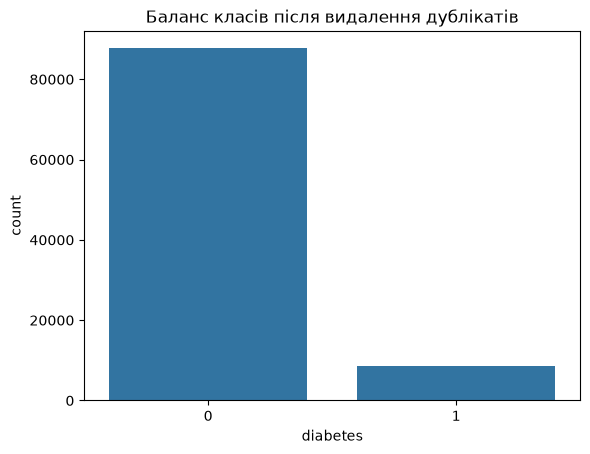

In [15]:
sns.countplot(data=df,x='diabetes',color='tab:blue')
plt.title('Баланс класів після видалення дублікатів')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [16]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression,RidgeClassifier,SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.metrics import classification_report,confusion_matrix,ConfusionMatrixDisplay,f1_score,recall_score,accuracy_score
from imblearn.over_sampling import SMOTE

In [17]:
X=df.drop(columns='diabetes')
y=df['diabetes']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print('Train:',len(X_train),'Test:',len(X_test))

Train: 76916 Test: 19230


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [18]:
X_train=pd.get_dummies(X_train,columns=['gender','smoking_history'],dtype=int)
X_test=pd.get_dummies(X_test,columns=['gender','smoking_history'],dtype=int)
X_test=X_test.reindex(columns=X_train.columns,fill_value=0)
print('Числові та закодовані ознаки:',list(X_train.columns))

Числові та закодовані ознаки: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Female', 'gender_Male', 'gender_Other', 'smoking_history_No Info', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']


In [19]:
display(X_train.describe())

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [20]:
target_corr=X_train.corrwith(y_train).sort_values(key=abs,ascending=False)
display(target_corr)

blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_No Info       -0.113053
smoking_history_former         0.096162
gender_Male                    0.040650
gender_Female                 -0.040533
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
dtype: float64

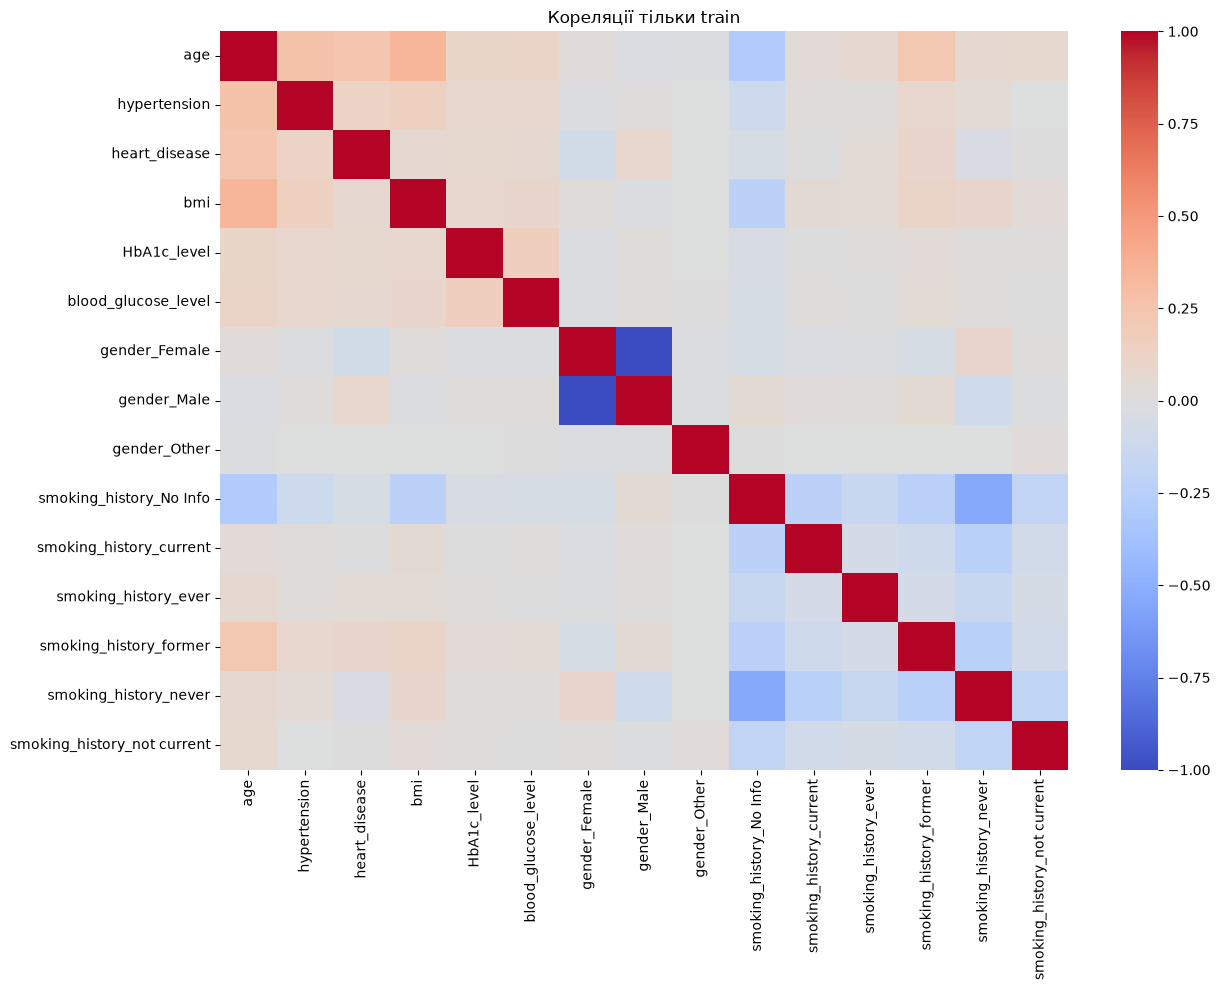

In [21]:
plt.figure(figsize=(13,10))
sns.heatmap(X_train.corr(),cmap='coolwarm',vmin=-1,vmax=1)
plt.title('Кореляції тільки train')
plt.tight_layout()
plt.show()

Виведено кореляції train з цільовим класом і між предикторами. Взаємозалежність One-Hot стовпців очікувана. Ознаки збережено: кореляція не доводить зайвості клінічних показників, а лінійні моделі використовують регуляризацію. Числові лідери за зв’язком із ціллю наведені у висновку.

Перевірити викиди **лише на навчальній вибірці**

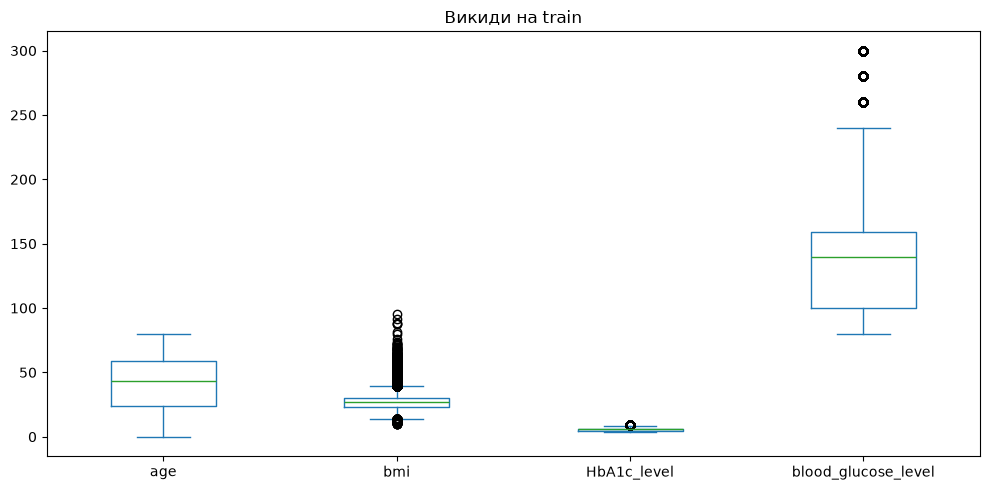

In [22]:
continuous_cols=['age','bmi','HbA1c_level','blood_glucose_level']
X_train[continuous_cols].plot.box(figsize=(10,5))
plt.title('Викиди на train')
plt.tight_layout()
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

Перевірити асиметрію розподілів ознак **на train**

In [23]:
display(X_train[continuous_cols].skew().rename('Асиметрія'))

age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
Name: Асиметрія, dtype: float64

In [24]:
display(pd.DataFrame({'Train':X_train.isna().sum(),'Test':X_test.isna().sum()}))

,Train,Test
age,0,0
hypertension,0,0
heart_disease,0,0
bmi,0,0
HbA1c_level,0,0
blood_glucose_level,0,0
gender_Female,0,0
gender_Male,0,0
gender_Other,0,0
smoking_history_No Info,0,0


Дублікати вилучено до поділу. Поділ стратифіковано, test не збалансовується. Викиди не видаляються, оскільки крайні клінічні показники можуть бути змістовними. Мітка No Info залишається категорією, а не вважається числовим пропуском.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` : для test.

In [25]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
print(X_train_scaled.shape,X_test_scaled.shape)

(76916, 15) (19230, 15)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [26]:
smote=SMOTE(random_state=42)
X_balanced,y_balanced=smote.fit_resample(X_train_scaled,y_train)
display(pd.DataFrame({'До':y_train.value_counts(),'Після SMOTE':pd.Series(y_balanced).value_counts()}))

,До,Після SMOTE
diabetes,,
0,70130,70130
1,6786,70130


Оголошуємо моделі

In [27]:
models={'LogisticRegression':LogisticRegression(max_iter=3000,random_state=42),'RidgeClassifier':RidgeClassifier(),'SGDClassifier':SGDClassifier(loss='log_loss',max_iter=3000,tol=1e-4,random_state=42),'SVC':SVC(C=1,kernel='rbf',random_state=42,cache_size=512)}
print(list(models))

['LogisticRegression', 'RidgeClassifier', 'SGDClassifier', 'SVC']


Навчити моделі, вивести матриці плутанини, класифікаційний звіт


LogisticRegression
              precision    recall  f1-score   support

           0     0.9870    0.8854    0.9334     17534
           1     0.4260    0.8791    0.5739      1696

    accuracy                         0.8849     19230
   macro avg     0.7065    0.8823    0.7537     19230
weighted avg     0.9375    0.8849    0.9017     19230



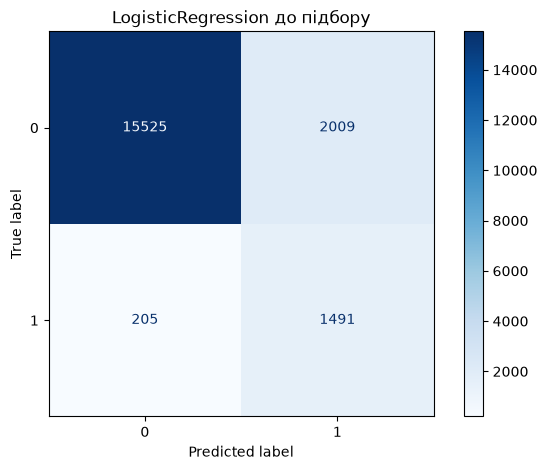

RidgeClassifier
              precision    recall  f1-score   support

           0     0.9866    0.8889    0.9352     17534
           1     0.4324    0.8750    0.5788      1696

    accuracy                         0.8877     19230
   macro avg     0.7095    0.8820    0.7570     19230
weighted avg     0.9377    0.8877    0.9038     19230



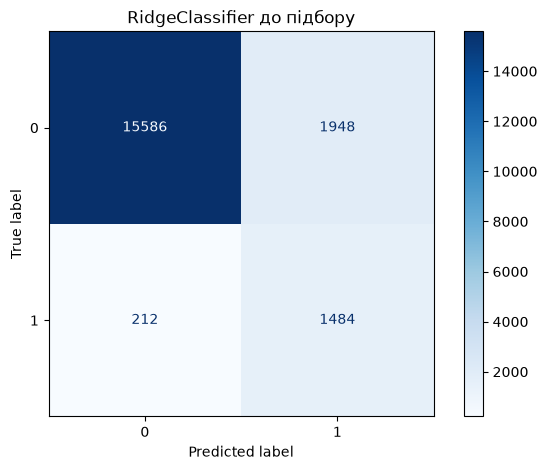

SGDClassifier
              precision    recall  f1-score   support

           0     0.9858    0.8888    0.9348     17534
           1     0.4301    0.8673    0.5751      1696

    accuracy                         0.8869     19230
   macro avg     0.7079    0.8781    0.7549     19230
weighted avg     0.9368    0.8869    0.9031     19230



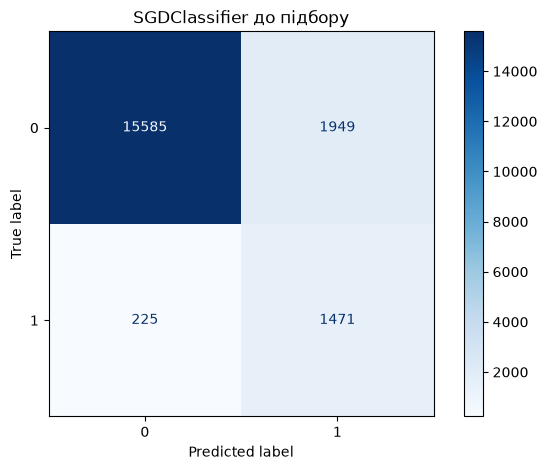

SVC
              precision    recall  f1-score   support

           0     0.9899    0.8814    0.9325     17534
           1     0.4253    0.9074    0.5791      1696

    accuracy                         0.8837     19230
   macro avg     0.7076    0.8944    0.7558     19230
weighted avg     0.9401    0.8837    0.9013     19230



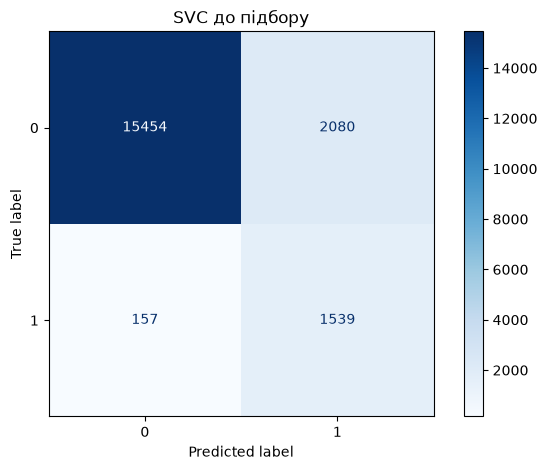

,F1,Recall,Accuracy
Модель,,,
LogisticRegression,0.573903,0.879127,0.884867
RidgeClassifier,0.578783,0.875000,0.887676
SGDClassifier,0.575059,0.867335,0.886947
SVC,0.579116,0.907429,0.883671


In [28]:
baseline_rows=[]
for name,model in models.items():
    model.fit(X_balanced,y_balanced)
    pred=model.predict(X_test_scaled)
    print(name)
    print(classification_report(y_test,pred,digits=4,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,pred,cmap='Blues')
    plt.title(name+' до підбору')
    plt.tight_layout()
    plt.show()
    baseline_rows.append({'Модель':name,'F1':f1_score(y_test,pred),'Recall':recall_score(y_test,pred),'Accuracy':accuracy_score(y_test,pred)})
baseline_results=pd.DataFrame(baseline_rows).set_index('Модель')
display(baseline_results)

Оптимізувати гіперпараметри


In [29]:
param_grids={
    'LogisticRegression':{'model__C':[0.1,1,10],'model__solver':['lbfgs','liblinear']},
    'RidgeClassifier':{'model__alpha':[0.1,1,10,100]},
    'SGDClassifier':{'model__alpha':[0.0001,0.001],'model__loss':['hinge','log_loss'],'model__penalty':['l2']},
    'SVC':{'model__C':[0.5,2],'model__kernel':['linear','rbf']}
}
print(param_grids)

{'LogisticRegression': {'model__C': [0.1, 1, 10], 'model__solver': ['lbfgs', 'liblinear']}, 'RidgeClassifier': {'model__alpha': [0.1, 1, 10, 100]}, 'SGDClassifier': {'model__alpha': [0.0001, 0.001], 'model__loss': ['hinge', 'log_loss'], 'model__penalty': ['l2']}, 'SVC': {'model__C': [0.5, 2], 'model__kernel': ['linear', 'rbf']}}


Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [30]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

LogisticRegression CV F1: 0.6412961389596904 Параметри: {'model__C': 10, 'model__solver': 'liblinear'} Ресурси: [300, 600, 1200]
              precision    recall  f1-score   support

           0     0.9870    0.8855    0.9335     17534
           1     0.4261    0.8791    0.5740      1696

    accuracy                         0.8849     19230
   macro avg     0.7065    0.8823    0.7537     19230
weighted avg     0.9375    0.8849    0.9018     19230



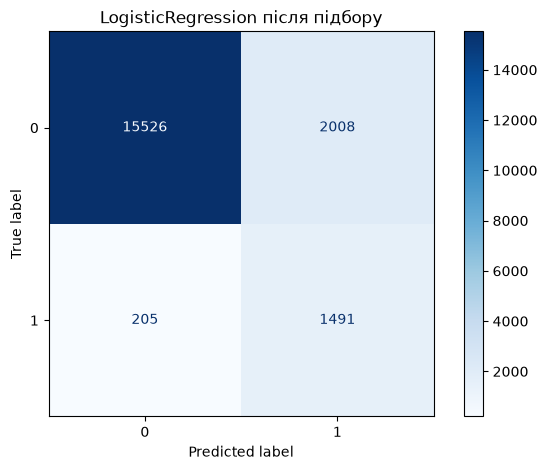

RidgeClassifier CV F1: 0.6246498599439776 Параметри: {'model__alpha': 100} Ресурси: [300, 600, 1200]
              precision    recall  f1-score   support

           0     0.9866    0.8889    0.9352     17534
           1     0.4324    0.8750    0.5788      1696

    accuracy                         0.8877     19230
   macro avg     0.7095    0.8820    0.7570     19230
weighted avg     0.9377    0.8877    0.9038     19230



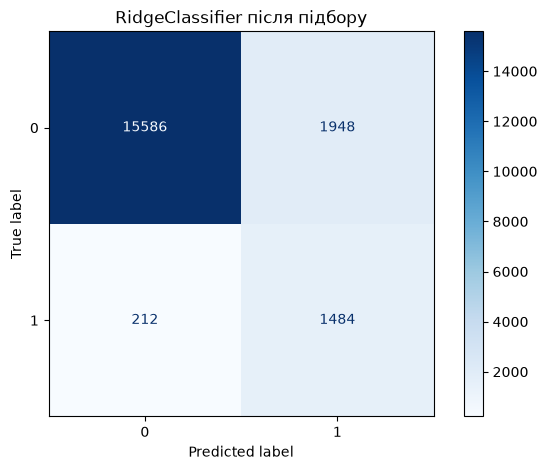

SGDClassifier CV F1: 0.6428488419045593 Параметри: {'model__alpha': 0.001, 'model__loss': 'log_loss', 'model__penalty': 'l2'} Ресурси: [300, 600, 1200]
              precision    recall  f1-score   support

           0     0.9870    0.8851    0.9332     17534
           1     0.4253    0.8791    0.5732      1696

    accuracy                         0.8846     19230
   macro avg     0.7061    0.8821    0.7532     19230
weighted avg     0.9374    0.8846    0.9015     19230



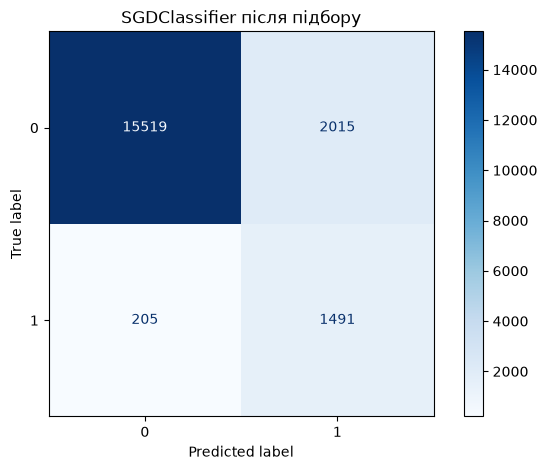

SVC CV F1: 0.6110714176131009 Параметри: {'model__C': 2, 'model__kernel': 'linear'} Ресурси: [300, 600, 1200]
              precision    recall  f1-score   support

           0     0.9877    0.8825    0.9321     17534
           1     0.4218    0.8862    0.5716      1696

    accuracy                         0.8828     19230
   macro avg     0.7048    0.8844    0.7519     19230
weighted avg     0.9378    0.8828    0.9003     19230



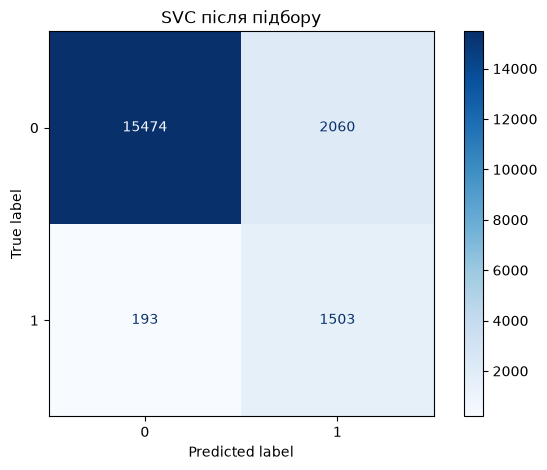

,CV F1,Test F1,Test recall
Модель,,,
LogisticRegression,0.641296,0.574013,0.879127
RidgeClassifier,0.624650,0.578783,0.875000
SGDClassifier,0.642849,0.573241,0.879127
SVC,0.611071,0.571592,0.886203


In [31]:
best_models={}
best_scores={}
best_parameters={}
tuned_rows=[]
cv=StratifiedKFold(3,shuffle=True,random_state=42)
for name,model in models.items():
    pipe=Pipeline([('scale',StandardScaler()),('smote',SMOTE(random_state=42)),('model',clone(model))])
    search=HalvingGridSearchCV(pipe,param_grids[name],cv=cv,scoring='f1',min_resources=300,factor=2,random_state=42,n_jobs=2,error_score='raise')
    search.fit(X_train,y_train)
    best_models[name]=search.best_estimator_
    best_scores[name]=search.best_score_
    best_parameters[name]=search.best_params_
    pred=search.predict(X_test)
    print(name,'CV F1:',search.best_score_,'Параметри:',search.best_params_,'Ресурси:',search.n_resources_)
    print(classification_report(y_test,pred,digits=4,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,pred,cmap='Blues')
    plt.title(name+' після підбору')
    plt.tight_layout()
    plt.show()
    tuned_rows.append({'Модель':name,'CV F1':search.best_score_,'Test F1':f1_score(y_test,pred),'Test recall':recall_score(y_test,pred)})
tuned_results=pd.DataFrame(tuned_rows).set_index('Модель')
display(tuned_results)

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [32]:
best_name=max(best_scores,key=best_scores.get)
best_model=best_models[best_name]
print('Найкраща за CV F1:',best_name,best_scores[best_name])

Найкраща за CV F1: SGDClassifier 0.6428488419045593


In [33]:
sample=X_test.sample(10,random_state=42)
display(pd.DataFrame({'Індекс':sample.index,'Істинний клас':y_test.loc[sample.index].values,'Передбачений клас':best_model.predict(sample)}))

,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


## Підсумкові висновки
Порівняння основних і додаткових моделей наведено нижче. Вибір основної моделі здійснюється лише за CV F1; масштабування та SMOTE під час пошуку виконуються всередині кожного навчального згину. Послідовне відсіювання використовує невеликі порції train, тому CV-оцінки менш стійкі, ніж оцінки на всьому train; фінальний обраний Pipeline перенавчається на всій навчальній вибірці. Звичайний SMOTE може утворювати дробові значення One-Hot ознак, що є обмеженням підходу з умови.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

XGBoost
              precision    recall  f1-score   support

           0     0.9788    0.9733    0.9761     17534
           1     0.7393    0.7824    0.7602      1696

    accuracy                         0.9565     19230
   macro avg     0.8591    0.8779    0.8682     19230
weighted avg     0.9577    0.9565    0.9570     19230



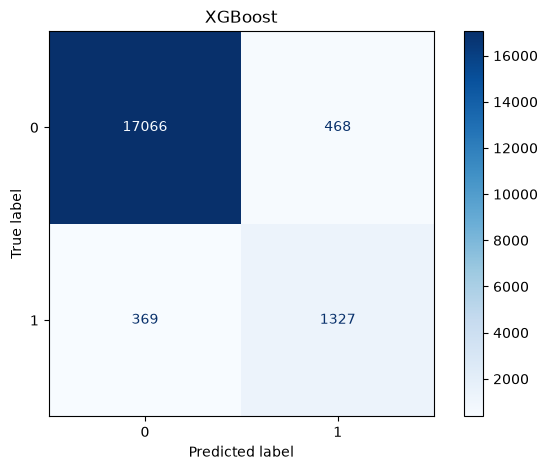

LightGBM
              precision    recall  f1-score   support

           0     0.9749    0.9883    0.9816     17534
           1     0.8591    0.7370    0.7934      1696

    accuracy                         0.9661     19230
   macro avg     0.9170    0.8627    0.8875     19230
weighted avg     0.9647    0.9661    0.9650     19230



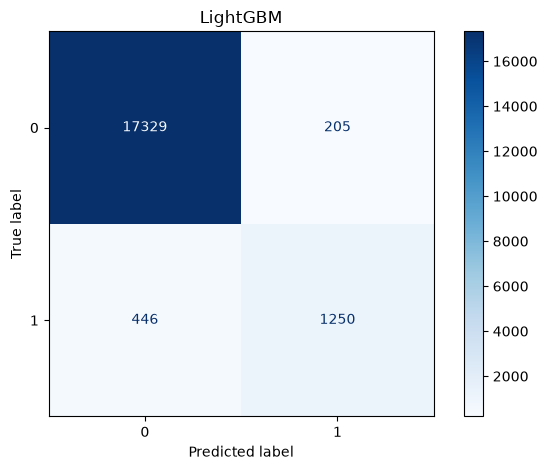

CatBoost
              precision    recall  f1-score   support

           0     0.9736    0.9946    0.9840     17534
           1     0.9279    0.7211    0.8115      1696

    accuracy                         0.9705     19230
   macro avg     0.9508    0.8578    0.8978     19230
weighted avg     0.9696    0.9705    0.9688     19230



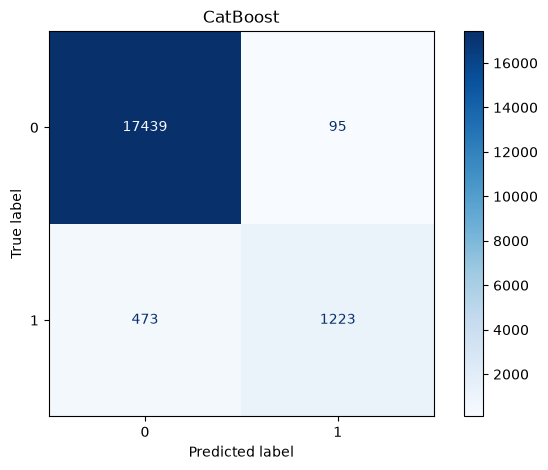

,Test F1,Test recall
Модель,,
XGBoost,0.760241,0.782429
LightGBM,0.793399,0.737028
CatBoost,0.811546,0.721108


In [34]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
extra_models={
    'XGBoost':XGBClassifier(n_estimators=200,max_depth=4,learning_rate=0.05,eval_metric='logloss',random_state=42,n_jobs=2),
    'LightGBM':LGBMClassifier(n_estimators=200,max_depth=5,num_leaves=20,learning_rate=0.05,random_state=42,n_jobs=2,verbosity=-1),
    'CatBoost':CatBoostClassifier(iterations=200,depth=5,learning_rate=0.05,random_seed=42,verbose=False,thread_count=2,allow_writing_files=False)
}
extra_rows=[]
for name,model in extra_models.items():
    model.fit(X_balanced,y_balanced)
    pred=model.predict(X_test_scaled).ravel()
    print(name)
    print(classification_report(y_test,pred,digits=4,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,pred,cmap='Blues')
    plt.title(name)
    plt.tight_layout()
    plt.show()
    extra_rows.append({'Модель':name,'Test F1':f1_score(y_test,pred),'Test recall':recall_score(y_test,pred)})
extra_results=pd.DataFrame(extra_rows).set_index('Модель')
display(extra_results)

## Загальний висновок
Після видалення 3854 дублікатів залишилося 96146 записів; частка класу diabetes=1 становить 8.82%. Найсильніші за абсолютною кореляцією з ціллю на train ознаки: blood_glucose_level, HbA1c_level, age. Клінічно значущі крайні значення збережено. За середнім CV F1 серед чотирьох основних моделей обрано **SGDClassifier** (0.6428), її параметри: `{'model__alpha': 0.001, 'model__loss': 'log_loss', 'model__penalty': 'l2'}`. На test вона має F1=0.5732, recall=0.8791; матриця помилок містить FP=2015 і FN=205. Додатково перевірено XGBoost, LightGBM і CatBoost; найвищий тестовий F1 серед них має CatBoost (0.8115), проте ці результати не використовувалися для повторного вибору основної моделі. Порівняння до та після підбору наведено у таблицях, і покращення кожної моделі не гарантується. Розділення та передобробка всередині CV запобігають витоку даних, а незмінний test зберігає реальний дисбаланс для підсумкової оцінки. Це навчальне порівняння моделей, а не перевірена медична діагностична система.